# 05 · Validation of the Volcano Activity Indicator (VAI)

Workshop 4, Part 1. How well does the weekly VAI line up with the US eruptions since 2010, how often does it raise a flag far from any eruption, and how much do the results depend on the weights?

* **Data:** the newest storytelling Gold file (`vai_weekly`: VAI, S and H per volcano and week since 2010) and the Silver eruptions (GVP). Notebooks may read Silver; only the dashboards are restricted to Gold.
* **The weekly VAI uses S (earthquakes) and H (eruptive history) only.** USGS HANS keeps no history of alert levels, so R cannot be rebuilt for past weeks.
* The VAI compares each volcano with its own past. **It is a monitoring aid, not an eruption forecast.** Rules: [`workshop_4/vai_indicator.md`](../workshop_4/vai_indicator.md).
* Charts use Seaborn (course recommendation); the figures are saved to `workshop_4/figures/` for the report.

In [1]:
import glob
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from dashboard.common.gold import load_gold   # same loader as the dashboards

FIGURES = ROOT / "workshop_4" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
OKABE_ITO = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]
THRESHOLD = 50          # ELEVATED or HIGH

snapshot = load_gold("storytelling", ROOT / "datalake_gold")
print("Gold file:", snapshot.path.name, "| generated", snapshot.generated_utc, "UTC")

weekly = (snapshot.section("vai_weekly")
          .pivot_table(index=["dimension", "period"], columns="metric", values="value").reset_index())
weekly["week"] = pd.to_datetime(weekly["period"])
weekly["vnum"] = weekly["dimension"].astype(int)
weekly["avg4"] = weekly.groupby("vnum")["vai_score"].transform(lambda x: x.rolling(4, min_periods=1).mean())


def silver(topic):
    df = pd.concat(pd.read_parquet(f) for f in glob.glob(str(ROOT / "datalake_silver" / topic / "*.parquet")))
    return df.sort_values("processed_utc").drop_duplicates("record_id", keep="last")


volcanoes = silver("volcanoes")[["vnum", "name"]]
eruptions = silver("eruptions").merge(volcanoes, on="vnum")
eruptions = eruptions[eruptions["start_time"].notna() & (eruptions["start_time"] >= "2010-01-01")].copy()
eruptions["start"] = eruptions["start_time"].dt.tz_convert(None)
eruptions["end"] = eruptions["end_time"].dt.tz_convert(None)
with_baseline = eruptions[eruptions["vnum"].isin(weekly["vnum"].unique())]
print(f"{weekly['vnum'].nunique()} volcanoes with a weekly history, {len(weekly):,} volcano-weeks")
print(f"US eruptions since 2010: {len(eruptions)}; at volcanoes with a seismic baseline: {len(with_baseline)}")

Gold file: storytelling_20261125_021243.parquet | generated 2026-11-25 02:12:43.415301 UTC


128 volcanoes with a weekly history, 112,768 volcano-weeks
US eruptions since 2010: 47; at volcanoes with a seismic baseline: 44


## 1. Hits and false alarms

* **Hit (Workshop 1 definition):** the weekly VAI reaches 50 (ELEVATED) in the 4 weeks before *or after* the eruption start. After the start H = 1 by construction, so part of these hits is circular.
* **Early hit:** the VAI reaches 50 in one of the 4 complete weeks that end before the start. The week in which the eruption starts is left out, because its H is already 1. This is the honest measure of an early signal.
* **False alarm rate:** share of volcano-weeks with VAI ≥ 50 that lie more than 8 weeks away from any eruption (from 8 weeks before its start to 8 weeks after its end; a continuing eruption runs to today).

Each measure is computed for the weekly VAI, for S alone (scaled to 0-100) and for the 4-week average that the dashboard draws.

In [2]:
WEEK = pd.Timedelta(weeks=1)


def before_window(e):
    # the 4 complete weeks that end before the eruption start (the start week itself has H = 1)
    return (weekly["vnum"] == e.vnum) & (weekly["week"] > e.start - 5 * WEEK) & (weekly["week"] + WEEK <= e.start)


def hit_rate(col, before_only):
    hits = []
    for e in with_baseline.itertuples():
        if before_only:
            window = before_window(e)
        else:
            window = ((weekly["vnum"] == e.vnum) & (weekly["week"] >= e.start - 4 * WEEK)
                      & (weekly["week"] < e.start + 4 * WEEK))
        hits.append(bool((weekly.loc[window, col] >= THRESHOLD).any()))
    return np.mean(hits)


far = pd.Series(True, index=weekly.index)
today = weekly["week"].max()
for e in eruptions.itertuples():
    end = today if e.is_continuing else (e.end if pd.notna(e.end) else e.start)
    near = ((weekly["vnum"] == e.vnum) & (weekly["week"] >= e.start - pd.Timedelta(weeks=8))
            & (weekly["week"] <= end + pd.Timedelta(weeks=8)))
    far &= ~near

weekly["seismic_100"] = weekly["seismic"] * 100
rows = []
for label, col in [("Weekly VAI", "vai_score"), ("S only", "seismic_100"), ("4-week average VAI", "avg4")]:
    rows += [{"signal": label, "measure": "Hit (before or after)", "rate": hit_rate(col, False)},
             {"signal": label, "measure": "Early hit (before only)", "rate": hit_rate(col, True)},
             {"signal": label, "measure": "False alarm rate", "rate": (weekly.loc[far, col] >= THRESHOLD).mean()}]
results = pd.DataFrame(rows)
print(f"{far.sum():,} volcano-weeks far from any eruption")
results.pivot(index="signal", columns="measure", values="rate").round(3)

110,592 volcano-weeks far from any eruption


measure,Early hit (before only),False alarm rate,Hit (before or after)
signal,,,
4-week average VAI,0.364,0.055,0.500
S only,0.523,0.172,0.682
Weekly VAI,0.523,0.141,0.705


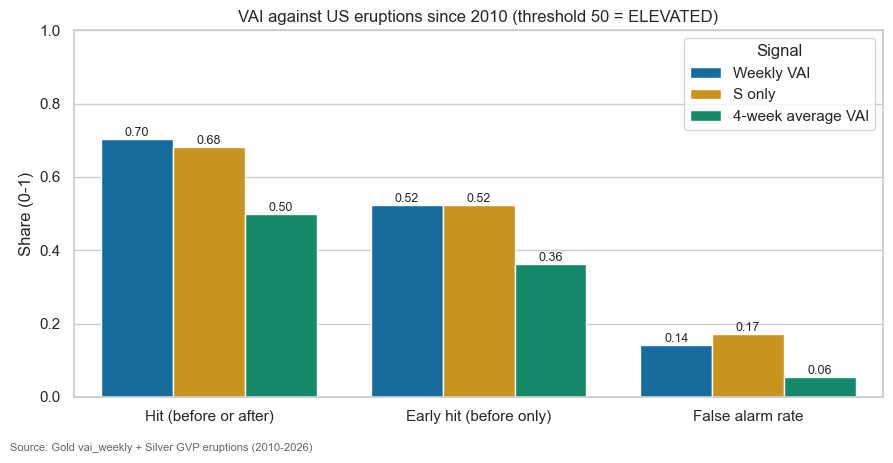

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=results, x="measure", y="rate", hue="signal", palette=OKABE_ITO[:3], ax=ax)
ax.set(title="VAI against US eruptions since 2010 (threshold 50 = ELEVATED)", xlabel="",
       ylabel="Share (0-1)", ylim=(0, 1))
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=9)
ax.legend(title="Signal", loc="upper right")
fig.text(0.01, -0.02, "Source: Gold vai_weekly + Silver GVP eruptions (2010-2026)", fontsize=8, color="#666666")
fig.tight_layout()
fig.savefig(FIGURES / "vai_hits_false_alarms.png", dpi=150, bbox_inches="tight")

## 2. Case studies

The Workshop 1 plan named Kilauea 2018, Mauna Loa 2022, Great Sitkin 2021 and Ahyi 2025. **GVP has no Kilauea eruption starting in 2018**: the 2018 lower East Rift Zone activity is the last phase of the 1983-2018 eruption, which started before the 2010 baseline. The Kilauea case therefore uses the summit eruption that started on **2020-12-20**. Each panel shows the year around the start: the 4-week average VAI (the dashboard line) and S on the same 0-100 scale.

,case,start,max VAI 4 weeks before,max S 4 weeks before,early hit
0,Kilauea,2020-12-20,91.9,0.92,True
1,Mauna Loa,2022-11-27,70.5,0.99,True
2,Great Sitkin,2021-05-25,88.3,0.86,True
3,Ahyi,2025-10-20,35.9,0.00,False


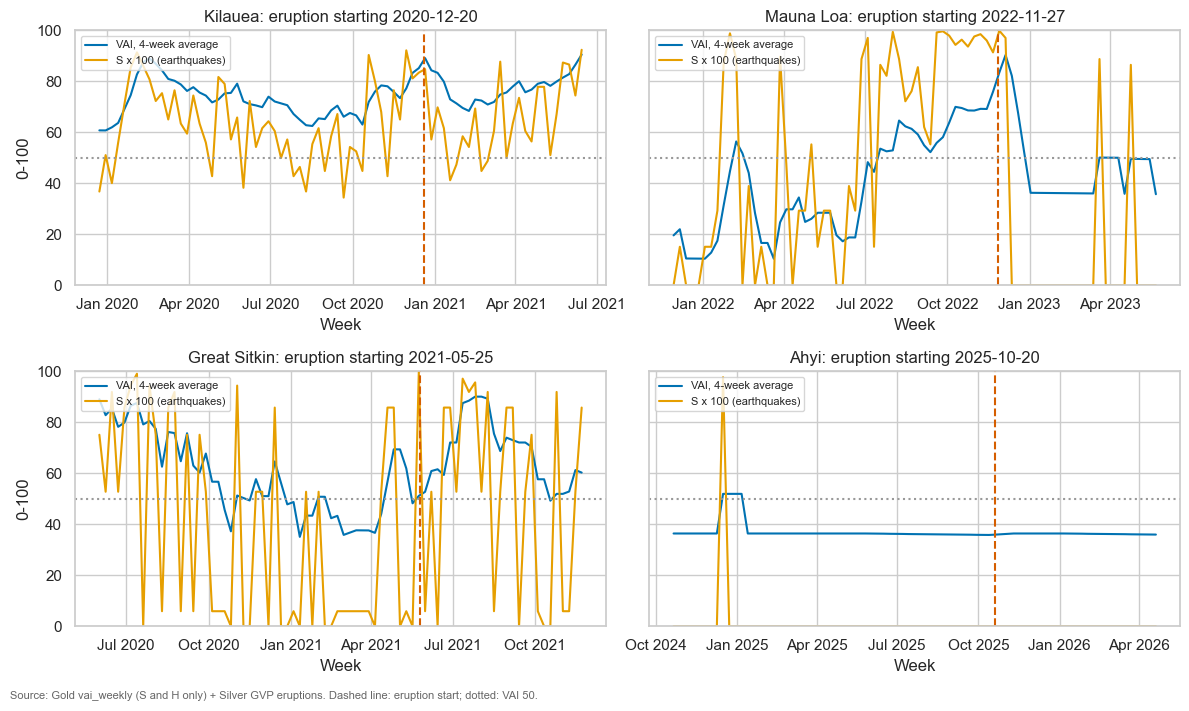

In [4]:
cases = [("Kilauea", "2020-12-20"), ("Mauna Loa", "2022-11-27"), ("Great Sitkin", "2021-05-25"), ("Ahyi", "2025-10-20")]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
summary = []
for ax, (name, start) in zip(axes.flat, cases):
    start = pd.Timestamp(start)
    vnum = volcanoes.loc[volcanoes["name"] == name, "vnum"].iloc[0]
    g = weekly[(weekly["vnum"] == vnum)
               & (weekly["week"].between(start - pd.Timedelta(weeks=52), start + pd.Timedelta(weeks=26)))]
    long = g.melt(id_vars="week", value_vars=["avg4", "seismic_100"], var_name="series", value_name="value")
    long["series"] = long["series"].map({"avg4": "VAI, 4-week average", "seismic_100": "S x 100 (earthquakes)"})
    sns.lineplot(data=long, x="week", y="value", hue="series", palette=[OKABE_ITO[0], OKABE_ITO[1]], ax=ax)
    ax.axvline(start, color=OKABE_ITO[5], linestyle="--")
    ax.axhline(THRESHOLD, color="#999999", linestyle=":")
    ax.set(title=f"{name}: eruption starting {start:%Y-%m-%d}", xlabel="Week", ylabel="0-100", ylim=(0, 100))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.legend(fontsize=8, loc="upper left")
    before = g[(g["week"] > start - pd.Timedelta(weeks=5)) & (g["week"] + pd.Timedelta(weeks=1) <= start)]
    summary.append({"case": name, "start": start.date(), "max VAI 4 weeks before": before["vai_score"].max(),
                    "max S 4 weeks before": before["seismic"].max(),
                    "early hit": bool((before["vai_score"] >= THRESHOLD).any())})
fig.text(0.01, -0.01, "Source: Gold vai_weekly (S and H only) + Silver GVP eruptions. Dashed line: eruption start; "
         "dotted: VAI 50.", fontsize=8, color="#666666")
fig.tight_layout()
fig.savefig(FIGURES / "vai_case_studies.png", dpi=150, bbox_inches="tight")
pd.DataFrame(summary).round(2)

## 3. Sensitivity to the weights

The weekly VAI combines S and H only, so only the share of S in their weights matters (default 0.35 / (0.35 + 0.20) = 0.64). The cell below recomputes the weekly VAI for shares between 0.3 and 0.9 and measures early hits and false alarms at the two thresholds used in the dashboard (50 = ELEVATED, 75 = HIGH).

threshold      VAI >= 50                       VAI >= 75                 
measure   Early hit rate False alarm rate Early hit rate False alarm rate
S share                                                                  
0.30               0.886            0.165          0.409            0.047
0.35               0.886            0.159          0.409            0.046
0.40               0.841            0.150          0.409            0.046
0.45               0.818            0.134          0.409            0.046
0.50               0.500            0.117          0.386            0.046
0.55               0.500            0.126          0.432            0.046
0.60               0.500            0.137          0.432            0.047
0.65               0.523            0.142          0.409            0.049
0.70               0.523            0.149          0.432            0.051
0.75               0.523            0.152          0.409            0.055
0.80               0.523            0.156          0.409            0.065
0.85               0.523            0.158          0.409            0.075
0.90               0.523            0.161          0.409            0.083

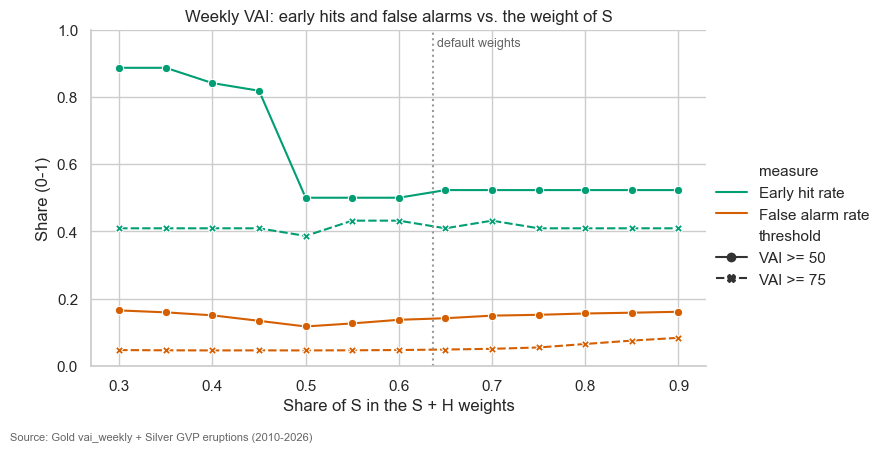

In [5]:
def early_hits(score, threshold):
    return np.mean([bool((score[before_window(e)] >= threshold).any()) for e in with_baseline.itertuples()])


sens = []
s, h = weekly["seismic"], weekly["eruptive"]
for share in np.round(np.arange(0.3, 0.91, 0.05), 2):
    score = 100 * (share * s + (1 - share) * h)
    score = score.where(h.notna(), 100 * s)          # no dated eruption: S alone, as the renormalisation does
    for threshold in (50, 75):
        label = f"VAI >= {threshold}"
        sens += [{"S share": share, "threshold": label, "measure": "Early hit rate",
                  "rate": early_hits(score, threshold)},
                 {"S share": share, "threshold": label, "measure": "False alarm rate",
                  "rate": (score[far] >= threshold).mean()}]
sens = pd.DataFrame(sens)

g = sns.relplot(data=sens, x="S share", y="rate", hue="measure", style="threshold", kind="line", markers=True,
                palette=[OKABE_ITO[2], OKABE_ITO[5]], height=4.2, aspect=1.7)
g.ax.axvline(0.35 / 0.55, color="#999999", linestyle=":")
g.ax.text(0.35 / 0.55 + 0.005, 0.95, "default weights", fontsize=9, color="#666666")
g.set(title="Weekly VAI: early hits and false alarms vs. the weight of S",
      xlabel="Share of S in the S + H weights", ylabel="Share (0-1)", ylim=(0, 1))
g.figure.text(0.01, -0.02, "Source: Gold vai_weekly + Silver GVP eruptions (2010-2026)", fontsize=8, color="#666666")
g.savefig(FIGURES / "vai_weight_sensitivity.png", dpi=150, bbox_inches="tight")
sens.pivot_table(index="S share", columns=["threshold", "measure"], values="rate").round(3)

## 4. Conclusions (Gold of 2026-11-25)

* **Coverage.** 44 of the 47 US eruptions since 2010 happened at a volcano with a seismic baseline (≥ 20 earthquakes M ≥ 1 within 30 km since 2010), so S could be judged for almost all of them.
* **Hits.** With the Workshop 1 definition the weekly VAI reaches ELEVATED around 70 % of the eruption starts, but that window includes the weeks after the start, where H = 1 by construction. Counting only the 4 complete weeks *before* the start, 52 % of the eruptions had an early signal, the same as S alone: at the default weights the early signal comes from the earthquakes, not from the eruptive history.
* **False alarms.** About 14 % of the volcano-weeks far from any eruption reach ELEVATED. The 4-week average the dashboard draws cuts that to about 6 %, at the cost of fewer early hits (36 %). The dashboard shows both lines; the ranking uses the current 7-day value.
* **Case studies.** Kilauea 2020, Mauna Loa 2022 and Great Sitkin 2021 were ELEVATED or HIGH in the weeks before the start; Mauna Loa shows months of rising seismicity. Ahyi 2025, a submarine volcano with sparse seismic coverage, was missed (S = 0), as the Workshop 1 design expected. Kilauea 2018 cannot be tested: in GVP it belongs to the 1983-2018 eruption.
* **Weights.** When H gets more than half of the weight (S share 0.45 or less), the early hit rate rises to 0.82-0.89, but only because frequently erupting volcanoes keep H close to 1 for years (decay of 25 years) and sit at ELEVATED most of the time. An equal split of S and H gives the fewest false alarms (0.12 against 0.14 at the default share of 0.64) with almost the same early hit rate (0.50 against 0.52). The default is kept as designed in Workshop 1; the equal split is the alternative to discuss. At the HIGH threshold (75) the false alarm rate stays near 0.05 for any weight.
* **Limitations.** The weekly S is in-sample (each week is compared with the whole 2010-present history); R has no history; the optional weekly-report bonus is not used; volcanoes without a seismic baseline only get H and R. The VAI is a monitoring aid, not an eruption forecast.